Setting up the simulation geometry


In [1]:
import shapely

geometry = shapely.Polygon(
    # complete area
    [
        (3.5, -2),
        (3.5, 8),
        (-3.5, 8),
        (-3.5, -2),
    ],
    holes=[
        # left barrier
        [
            (-0.7, -1.1),
            (-0.25, -1.1),
            (-0.25, -0.15),
            (-0.4, 0.0),
            (-2.8, 0.0),
            (-2.8, 6.7),
            (-3.05, 6.7),
            (-3.05, -0.3),
            (-0.7, -0.3),
            (-0.7, -1.0),
        ],
        # right barrier
        [
            (0.25, -1.1),
            (0.7, -1.1),
            (0.7, -0.3),
            (3.05, -0.3),
            (3.05, 6.7),
            (2.8, 6.7),
            (2.8, 0.0),
            (0.4, 0.0),
            (0.25, -0.15),
            (0.25, -1.1),
        ],
    ],
)

In [2]:
exit_polygon = shapely.Polygon(
    [(-0.2, -1.9), (0.2, -1.9), (0.2, -1.7), (-0.2, -1.7)]
)

In [3]:
import pandas

experiment_data = pandas.read_csv(
    "demo-data/bottleneck/040_c_56_h-.txt",
    comment="#",
    sep="\t",
    header=None,
    names=["id", "frame", "x", "y", "z"],
)
start_positions = experiment_data[experiment_data.frame == 0][["x", "y"]].values

In [4]:
import pathlib

import jupedsim as jps

trajectory_file = "bottleneck_cfsm.sqlite"
simulation_cfsm = jps.Simulation(
    model=jps.CollisionFreeSpeedModel(),
    geometry=geometry,
    trajectory_writer=jps.SqliteTrajectoryWriter(
        output_file=pathlib.Path(trajectory_file)
    ),
)

In [5]:
exit_id = simulation_cfsm.add_exit_stage(exit_polygon)
journey = jps.JourneyDescription([exit_id])
journey_id = simulation_cfsm.add_journey(journey)

In [6]:
for position in start_positions:
    simulation_cfsm.add_agent(
        jps.CollisionFreeSpeedModelAgentParameters(
            journey_id=journey_id,
            stage_id=exit_id,
            position=position,
            radius=0.12,
        )
    )

In [7]:
while (
    simulation_cfsm.agent_count() > 0
    and simulation_cfsm.iteration_count() < 10000
):
    simulation_cfsm.iterate()

simulation_cfsm._writer.close()

In [8]:
import pedpy
from jupedsim.internal.notebook_utils import animate, read_sqlite_file

trajectory_data, walkable_area = read_sqlite_file(trajectory_file)
speed = pedpy.compute_individual_speed(traj_data=trajectory_data, frame_step=5)
speed = speed.merge(trajectory_data.data, on=["id", "frame"], how="left")

animate(trajectory_data, walkable_area)

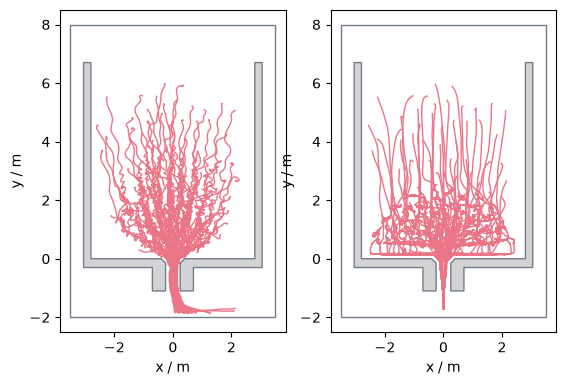

In [9]:
import pathlib

import matplotlib.pyplot as plt
import pedpy

experimental_trajectories = pedpy.load_trajectory(
    trajectory_file=pathlib.Path("demo-data/bottleneck/040_c_56_h-.txt")
)

cfsm_data, walkable_area = read_sqlite_file(trajectory_file)

fig = plt.figure()

ax1 = fig.add_subplot(121, aspect="equal")
ax1.set_title("experimental data")
pedpy.plot_trajectories(
    traj=experimental_trajectories,
    axes=ax1,
    walkable_area=pedpy.WalkableArea(geometry),
)

ax2 = fig.add_subplot(122, aspect="equal")
ax2.set_title("Collision free speed model")
pedpy.plot_trajectories(
    traj=cfsm_data, axes=ax2, walkable_area=pedpy.WalkableArea(geometry)
)
plt.show()

In [10]:
import pedpy

measurement_line = pedpy.MeasurementLine([(0.35, 0), (-0.35, 0)])

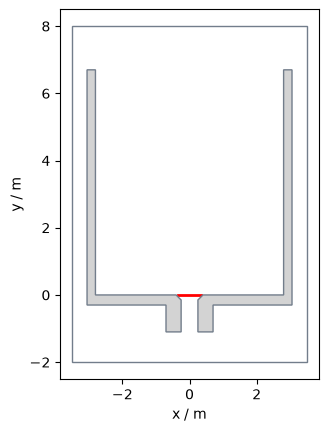

In [11]:
import pedpy

pedpy.plot_measurement_setup(
    walkable_area=walkable_area,
    measurement_lines=[measurement_line],
    ml_color="red",
    ml_width=2,
).set_aspect("equal")
plt.show()

In [12]:
import pedpy

nt_experiment, _ = pedpy.compute_n_t(
    traj_data=experimental_trajectories,
    measurement_line=measurement_line,
)

nt_cfsm, _ = pedpy.compute_n_t(
    traj_data=cfsm_data,
    measurement_line=measurement_line,
)

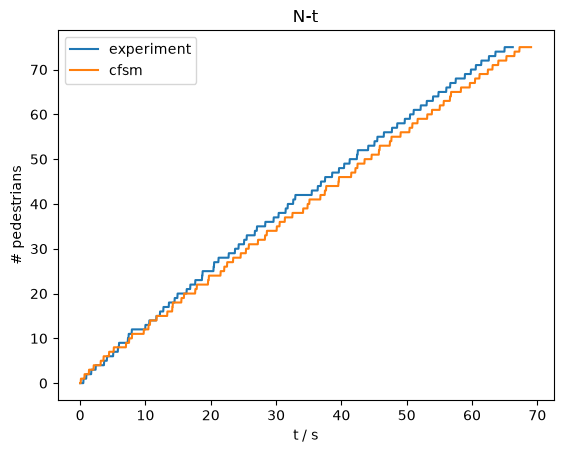

In [13]:
fig = plt.figure()
ax = fig.add_subplot(111)
ax.set_title("N-t")
ax.plot(
    nt_experiment["time"],
    nt_experiment["cumulative_pedestrians"],
    label="experiment",
)
ax.plot(nt_cfsm["time"], nt_cfsm["cumulative_pedestrians"], label="cfsm")
ax.legend()
ax.set_xlabel("t / s")
ax.set_ylabel("# pedestrians")
plt.show()